<h1 style="color:red; text-align:center;">Assignment (Questions): Penguins</h1>
<p style="color:red; text-align:center;">Instructor: Dr. Khaled Mohamad</p>

## Your Role

You are a junior data analyst at a wildlife research center. Your team collected measurements of penguins from different islands. Management wants you to **clean the data**, **explore patterns**, and finally build a **simple model** to predict the penguin species.

---

### The work is structured as follows:

- Part A: Understanding the Data
- Part B: Filtering, Sorting, Aggregation
- Part C: Visualization & Interpretation
- Part D: Apply ML model

## Import Required Modules, Libraries, and Functions in the Cell Below

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# You need the following functions (copy them)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Part A: Understanding the Dataset

## Q1: Load the `penguins` dataset from seaborn into a DataFrame named `df` and display the first 5 rows.

In [2]:
df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Q2: Print the following:

1. dataset shape,
2. column names,
3. data types.

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (344, 7)


In [4]:
print("Column names:", df.columns.tolist())

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [5]:
print("Data types:")
print(df.dtypes)

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object


## Q3: Check for missing values in each column:

In [6]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

## Q4: Create a **cleaned copy** called `df_clean` by:

1. Removing fully duplicated rows (if any)
2. Handling missing values:
    - For numeric columns: fill missing values with the **median**
    - For categorical columns: fill missing values with the **mode**

Then verify there are **no missing values** remaining.

In [7]:
df_clean = df.copy()
print("Duplicated rows found:", df_clean.duplicated().sum())

Duplicated rows found: 0


In [8]:
# 1) Drop duplicates
df_clean = df_clean.drop_duplicates()
print("Shape after dropping duplicates:", df_clean.shape)

Shape after dropping duplicates: (344, 7)


In [9]:
# 2) Fill missing values
num_cols = df_clean.select_dtypes(include=[np.number]).columns
cat_cols = df_clean.select_dtypes(exclude=[np.number]).columns

for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

In [10]:
# Verify
print("Total missing values remaining:", df_clean.isnull().sum().sum())
df_clean.isnull().sum()

Total missing values remaining: 0


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

# Part B: Filtering, Sorting, and Aggregation

## Q5: Filter the dataset to include only penguins from the island `"Biscoe"`.

Store the result in `biscoe_df` and print its shape.

In [11]:
biscoe_df = df_clean[df_clean["island"] == "Biscoe"]
print("Shape of biscoe_df:", biscoe_df.shape)

Shape of biscoe_df: (168, 7)


## Q6: Find all penguins with:

- `body_mass_g` greater than the **overall mean** body mass
- AND `sex` equal to `"Male"`

Store the result in `heavy_males` and display the first 5 rows.

In [12]:
mean_mass = df_clean["body_mass_g"].mean()
print("Overall mean body mass:", round(mean_mass, 2))

heavy_males = df_clean[(df_clean["body_mass_g"] > mean_mass) & (df_clean["sex"] == "Male")]
heavy_males.head()

Overall mean body mass: 4200.87


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,Male
14,Adelie,Torgersen,34.6,21.1,198.0,4400.0,Male
17,Adelie,Torgersen,42.5,20.7,197.0,4500.0,Male
39,Adelie,Dream,39.8,19.1,184.0,4650.0,Male


## Q7: Sort `df_clean` by:

1. `body_mass_g` (descending)
2. then `bill_length_mm` (ascending)

Show the top 10 rows.

In [13]:
df_clean.sort_values(by=["body_mass_g", "bill_length_mm"], ascending=[False, True]).head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male
299,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,Male
331,Gentoo,Biscoe,49.8,15.9,229.0,5950.0,Male
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,Male
235,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,Male
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,Male
295,Gentoo,Biscoe,48.6,16.0,230.0,5800.0,Male


## Q8: Compute the following aggregations:

1. Mean `body_mass_g` per `species`. Sort values in descending order.
2. Mean `bill_length_mm` per (`species`, `sex`)
3. Count of records per `island`

In [14]:
# 1) Mean body mass per species
df_clean.groupby("species")["body_mass_g"].mean().sort_values(ascending=False)

species
Gentoo       5067.741935
Chinstrap    3733.088235
Adelie       3702.960526
Name: body_mass_g, dtype: float64

In [15]:
# 2) Mean bill length per (species, sex)
df_clean.groupby(["species", "sex"])["bill_length_mm"].mean()

species    sex   
Adelie     Female    37.257534
           Male      40.280380
Chinstrap  Female    46.573529
           Male      51.094118
Gentoo     Female    45.563793
           Male      49.164394
Name: bill_length_mm, dtype: float64

In [16]:
# 3) Count per island
df_clean.groupby("island").size()

island
Biscoe       168
Dream        124
Torgersen     52
dtype: int64

## Q9: Feature engineering:

Create a new column `bill_ratio` = `bill_length_mm` / `bill_depth_mm`.

1. Add it to `df_clean`
2. Show summary statistics for `bill_ratio`
3. Identify which species has the **highest average bill_ratio**

In [17]:
#1) Add it to `df_clean`
df_clean["bill_ratio"] = df_clean["bill_length_mm"] / df_clean["bill_depth_mm"]
df_clean[["bill_length_mm", "bill_depth_mm", "bill_ratio"]].head()

,bill_length_mm,bill_depth_mm,bill_ratio
0,39.10,18.7,2.090909
1,39.50,17.4,2.270115
2,40.30,18.0,2.238889
3,44.45,17.3,2.569364
4,36.70,19.3,1.901554


In [18]:
#2) Show summary statistics for `bill_ratio`
df_clean["bill_ratio"].describe()

count    344.000000
mean       2.605438
std        0.495930
min        1.639810
25%        2.161882
50%        2.571484
75%        3.097572
max        3.612676
Name: bill_ratio, dtype: float64

In [19]:
#3) Identify which species has the **highest average bill_ratio**
avg_ratio = df_clean.groupby("species")["bill_ratio"].mean().sort_values(ascending=False)
print(avg_ratio)
print("\nSpecies with the highest average bill_ratio:", avg_ratio.idxmax())

species
Gentoo       3.170703
Chinstrap    2.653756
Adelie       2.122684
Name: bill_ratio, dtype: float64

Species with the highest average bill_ratio: Gentoo


# Part C: Visualization and Interpretation

## Q10: Create the following plots using `df_clean`:

1. Bar plot: count of penguins per species
2. Scatter plot: `bill_length_mm` vs `bill_depth_mm` (color by species)

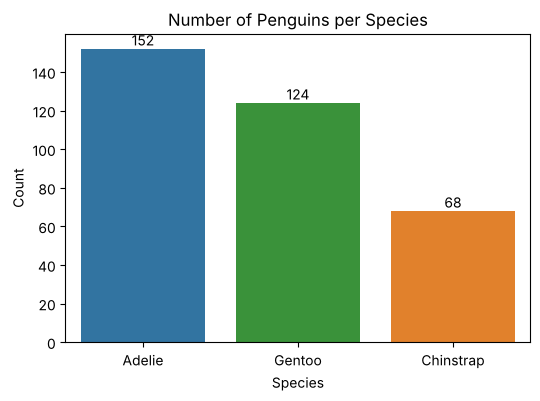

In [20]:
# 1) Count per species (bar)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_clean, x="species", hue="species", order=df_clean["species"].value_counts().index)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Number of Penguins per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

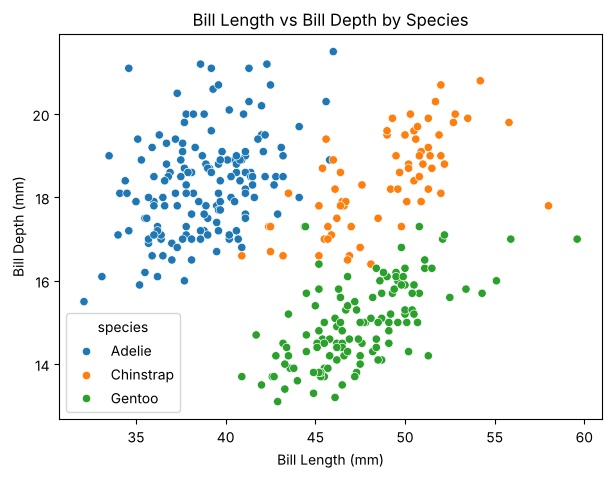

In [21]:
# 2) Scatter: bill length vs bill depth (color by species)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="bill_length_mm", y="bill_depth_mm", hue="species")
plt.title("Bill Length vs Bill Depth by Species")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.show()

## Q11: Create a box plot of `body_mass_g` by species.

Then write **2–3 sentences** interpreting what you observe.

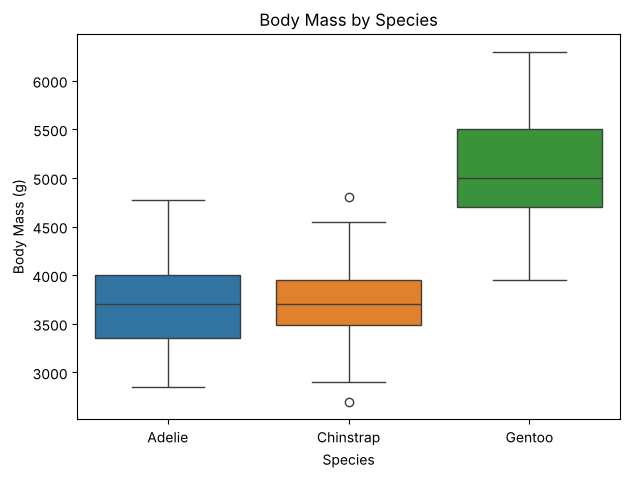

In [22]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x="species", y="body_mass_g", hue="species")
plt.title("Body Mass by Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")
plt.show()

**Interpretation**

- Gentoo penguins are clearly the heaviest, with a median body mass of about 5000 g, while Adelie and Chinstrap both have a median of about 3700 g.
- The Adelie and Chinstrap boxes overlap almost completely, so body mass alone cannot separate these two species, but it separates Gentoo from the other two very well.

## Q12: Compute a correlation matrix for numeric features and visualize it as a heatmap.

                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm               1.00          -0.24               0.66   
bill_depth_mm               -0.24           1.00              -0.58   
flipper_length_mm            0.66          -0.58               1.00   
body_mass_g                  0.59          -0.47               0.87   
bill_ratio                   0.78          -0.78               0.81   

                   body_mass_g  bill_ratio  
bill_length_mm            0.59        0.78  
bill_depth_mm            -0.47       -0.78  
flipper_length_mm         0.87        0.81  
body_mass_g               1.00        0.70  
bill_ratio                0.70        1.00  


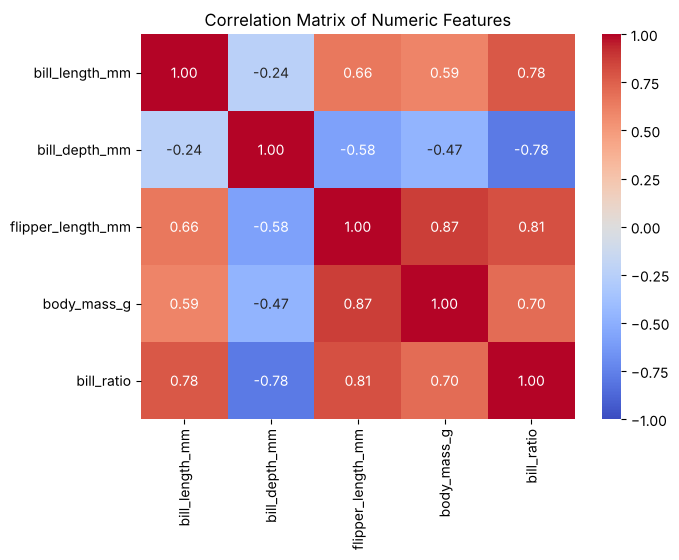

In [23]:
corr = df_clean.select_dtypes(include=[np.number]).corr()
print(corr.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numeric Features")
plt.show()

# Part D: Machine Learning

## Q13: Define:

- target `y` = `species`
- features `X` = all other columns EXCEPT `species`

Then split into train/test using:

- test_size = 0.2
- random_state = 42
- stratify by y

In [24]:
y = df_clean["species"]
X = df_clean.drop(columns=["species"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (275, 7) | X_test: (69, 7)
y_train: (275,) | y_test: (69,)


## Q14: Preprocessing Data for ML Training

**This step has already been completed for you. It will be explicitly explained and discussed in detail during class.**

We did the following:

- Handle missing values (even if we cleaned, do it properly in pipeline)
- One-hot encode categorical columns (`sex`, `island`)
- Standardize numeric columns

Note: You should copy paste this code and run it in the same order as the previous questions.

In [25]:
# Identify columns by type
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

## Q15: Train models:

1. **KNN Classifier** with `n_neighbors=5`

In [26]:
# 1) KNN pipeline
knn_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

In [27]:
#Train the model using the fit method
knn_model.fit(X_train, y_train);

In [28]:
# Predict on the X_test
knn_pred = knn_model.predict(X_test)

In [29]:
#calculate and print the accuracy based on the prediction of the X_test
knn_acc = accuracy_score(y_test, knn_pred)
print("KNN accuracy:", round(knn_acc, 4))

KNN accuracy: 0.9855


2. **Logistic Regression** (multiclass) with `max_iter=2000`

In [30]:
# 2) Logistic Regression pipeline
logreg_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])

In [31]:
# Train the model using the fit method
logreg_model.fit(X_train, y_train);

In [32]:
# Predict on the X_test
logreg_pred = logreg_model.predict(X_test)

In [33]:
#calculate and print the accuracy based on the prediction of the X_test
logreg_acc = accuracy_score(y_test, logreg_pred)
print("Logistic Regression accuracy:", round(logreg_acc, 4))

Logistic Regression accuracy: 1.0


## Q16: Conclude based on the accuracy results

**Answer:**

Both models perform very well: KNN reaches an accuracy of about 98.6% (68 of 69 test penguins correct) and Logistic Regression reaches 100%. The three species are well separated by their measurements, as the scatter plot and box plot showed, so even simple models can predict the species almost perfectly. Logistic Regression is slightly better, but the gap is a single test sample out of 69, so it is not strong evidence that one model is better. A larger test set or cross-validation would be needed to compare them reliably.